<a href="https://colab.research.google.com/github/azelepou/IntroMachineLearning/blob/main/ML_HW_AnatolyZelepouga_801236217_HW5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PROBLEM 1: QUADRATIC TEMPERATURE MODEL
alpha=0.1, epoch=500, MSE=2.090720
alpha=0.1, epoch=1000, MSE=2.090720
alpha=0.1, epoch=1500, MSE=2.090720
alpha=0.1, epoch=2000, MSE=2.090720
alpha=0.1, epoch=2500, MSE=2.090720
alpha=0.1, epoch=3000, MSE=2.090720
alpha=0.1, epoch=3500, MSE=2.090720
alpha=0.1, epoch=4000, MSE=2.090720
alpha=0.1, epoch=4500, MSE=2.090720
alpha=0.1, epoch=5000, MSE=2.090720
alpha=0.01, epoch=500, MSE=2.091741
alpha=0.01, epoch=1000, MSE=2.090720
alpha=0.01, epoch=1500, MSE=2.090720
alpha=0.01, epoch=2000, MSE=2.090720
alpha=0.01, epoch=2500, MSE=2.090720
alpha=0.01, epoch=3000, MSE=2.090720
alpha=0.01, epoch=3500, MSE=2.090720
alpha=0.01, epoch=4000, MSE=2.090720
alpha=0.01, epoch=4500, MSE=2.090720
alpha=0.01, epoch=5000, MSE=2.090720
alpha=0.001, epoch=500, MSE=25.472835
alpha=0.001, epoch=1000, MSE=7.689418
alpha=0.001, epoch=1500, MSE=3.727660
alpha=0.001, epoch=2000, MSE=2.627357
alpha=0.001, epoch=2500, MSE=2.276244
alpha=0.001, epoch=3000, MSE=2.156276
alpha

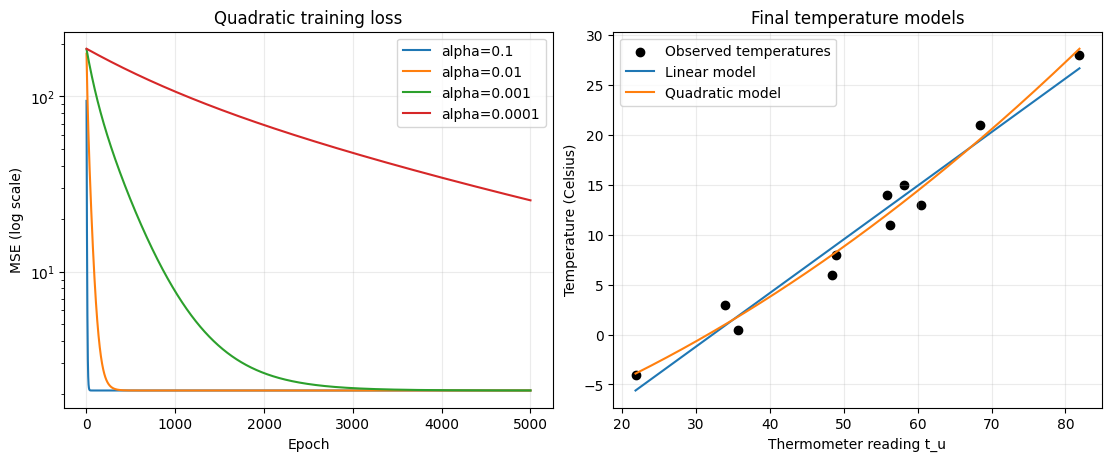


Housing rows: 545, training: 436, validation: 109
Prices are in millions; validation accuracy is reported as R2.

PROBLEM 2: HOUSING REGRESSION
alpha=0.1, epoch=500, train MSE=1.547089, val MSE=1.501831, val R2=0.574264
alpha=0.1, epoch=1000, train MSE=1.547089, val MSE=1.501831, val R2=0.574264
alpha=0.1, epoch=1500, train MSE=1.547089, val MSE=1.501831, val R2=0.574264
alpha=0.1, epoch=2000, train MSE=1.547089, val MSE=1.501831, val R2=0.574264
alpha=0.1, epoch=2500, train MSE=1.547089, val MSE=1.501831, val R2=0.574264
alpha=0.1, epoch=3000, train MSE=1.547089, val MSE=1.501831, val R2=0.574264
alpha=0.1, epoch=3500, train MSE=1.547089, val MSE=1.501831, val R2=0.574264
alpha=0.1, epoch=4000, train MSE=1.547089, val MSE=1.501831, val R2=0.574264
alpha=0.1, epoch=4500, train MSE=1.547089, val MSE=1.501831, val R2=0.574264
alpha=0.1, epoch=5000, train MSE=1.547089, val MSE=1.501831, val R2=0.574264
alpha=0.01, epoch=500, train MSE=1.547090, val MSE=1.501428, val R2=0.574378
alpha=0.0

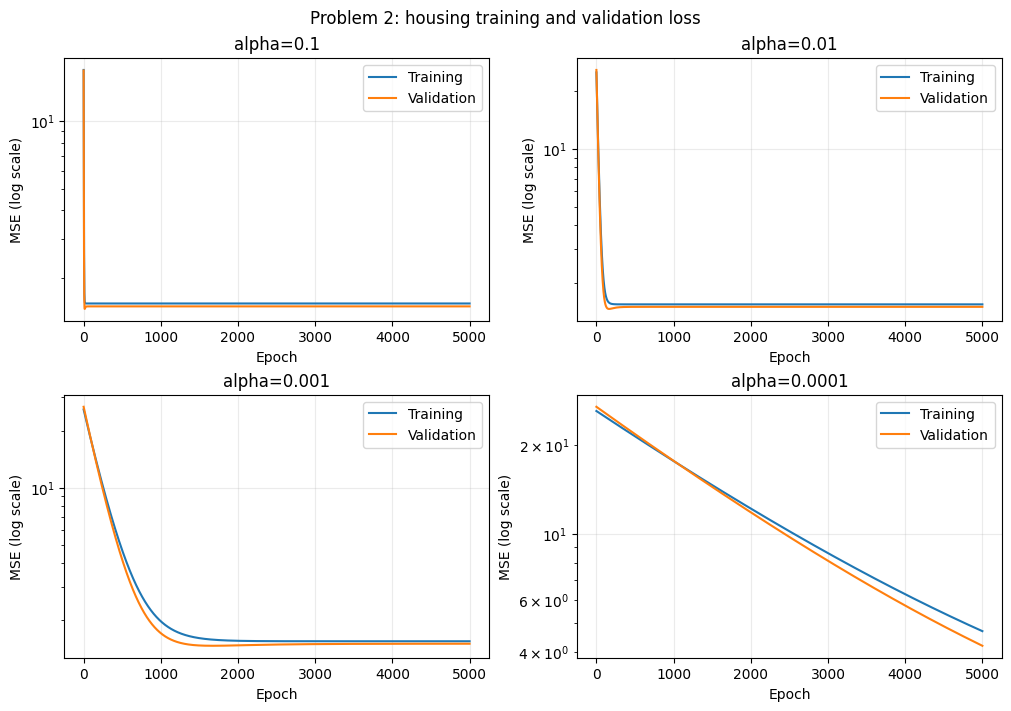


PROBLEM 3: HOUSING REGRESSION
alpha=0.1, epoch=500, train MSE=1.134846, val MSE=1.088776, val R2=0.691356
alpha=0.1, epoch=1000, train MSE=1.134846, val MSE=1.088776, val R2=0.691356
alpha=0.1, epoch=1500, train MSE=1.134846, val MSE=1.088776, val R2=0.691356
alpha=0.1, epoch=2000, train MSE=1.134846, val MSE=1.088776, val R2=0.691356
alpha=0.1, epoch=2500, train MSE=1.134846, val MSE=1.088776, val R2=0.691356
alpha=0.1, epoch=3000, train MSE=1.134846, val MSE=1.088776, val R2=0.691356
alpha=0.1, epoch=3500, train MSE=1.134846, val MSE=1.088776, val R2=0.691356
alpha=0.1, epoch=4000, train MSE=1.134846, val MSE=1.088776, val R2=0.691356
alpha=0.1, epoch=4500, train MSE=1.134846, val MSE=1.088776, val R2=0.691356
alpha=0.1, epoch=5000, train MSE=1.134846, val MSE=1.088776, val R2=0.691356
alpha=0.01, epoch=500, train MSE=1.134849, val MSE=1.088783, val R2=0.691354
alpha=0.01, epoch=1000, train MSE=1.134846, val MSE=1.088781, val R2=0.691354
alpha=0.01, epoch=1500, train MSE=1.134846, v

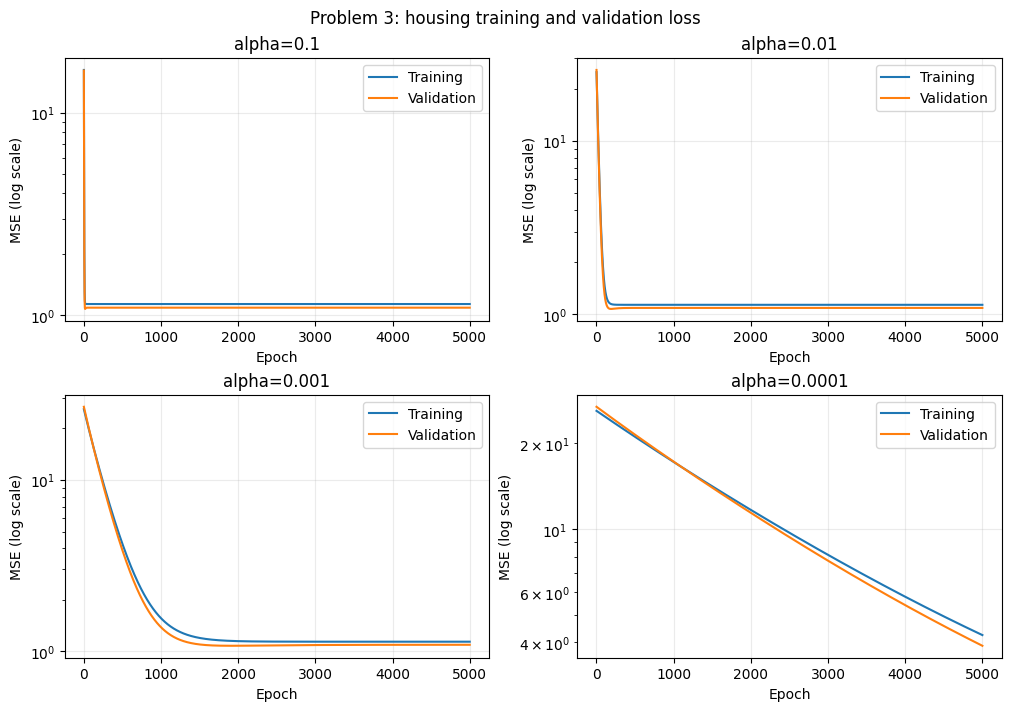


HOMEWORK 2 COMPARISON
                                model  validation_MSE
                     HW2: five inputs        1.501830
                     HW5: five inputs        1.501410
                   HW2: eleven inputs        1.131846
HW5: all inputs, including furnishing        1.088774
HW2 values are rounded report values converted from half-MSE to MSE.
Problem 3 adds furnishing status, so its inputs differ from HW2's eleven-input model.
All runs use 5000 epochs. The selected housing models minimize final validation MSE.

Finished. Three figures were displayed and saved as PNG files.


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

learning_rates = [0.1, 0.01, 0.001, 0.0001]
epochs = 5000
random_seed = 42
torch.set_default_dtype(torch.float64)


def train_model(X, y, alpha, X_val=None, y_val=None,
                initial=None, verbose=True):
    if initial is None:
        theta = torch.zeros(X.shape[1], requires_grad=True)
    else:
        theta = torch.tensor(initial, requires_grad=True)

    train_history = []
    val_history = []
    checkpoints = []

    for epoch in range(1, epochs + 1):
        predictions = X @ theta
        loss = torch.mean((predictions - y) ** 2)
        loss.backward()

        with torch.no_grad():
            theta -= alpha * theta.grad
            theta.grad.zero_()
            train_loss = torch.mean((X @ theta - y) ** 2).item()
            if not np.isfinite(train_loss):
                raise ValueError("Training diverged. Check input scaling.")
            train_history.append(train_loss)

            if X_val is not None:
                val_predictions = X_val @ theta
                val_loss = torch.mean((val_predictions - y_val) ** 2).item()
                total = torch.sum((y_val - y_val.mean()) ** 2)
                residual = torch.sum((y_val - val_predictions) ** 2)
                val_r2 = (1 - residual / total).item()
                val_history.append(val_loss)

        if epoch % 500 == 0:
            if X_val is None:
                checkpoints.append([alpha, epoch, train_loss])
                if verbose:
                    print(f"alpha={alpha:g}, epoch={epoch}, MSE={train_loss:.6f}")
            else:
                checkpoints.append([alpha, epoch, train_loss, val_loss, val_r2])
                if verbose:
                    print(f"alpha={alpha:g}, epoch={epoch}, "
                          f"train MSE={train_loss:.6f}, "
                          f"val MSE={val_loss:.6f}, val R2={val_r2:.6f}")

    return {"alpha": alpha, "theta": theta.detach().numpy().copy(),
            "train": np.array(train_history), "val": np.array(val_history),
            "checkpoints": checkpoints}


# %% PROBLEM 1
# Problem 1a
t_u = np.array([35.7, 55.9, 58.2, 81.9, 56.3, 48.9,
                33.9, 21.8, 48.4, 60.4, 68.4])
t_c = np.array([0.5, 14.0, 15.0, 28.0, 11.0, 8.0,
                3.0, -4.0, 6.0, 13.0, 21.0])

temperature_mean = t_u.mean()
temperature_std = t_u.std()
z = (t_u - temperature_mean) / temperature_std

X_temperature = torch.tensor(np.column_stack((np.ones(len(z)), z, z ** 2)))
y_temperature = torch.tensor(t_c)
temperature_runs = []
temperature_rows = []

# Problem 1b
print("PROBLEM 1: QUADRATIC TEMPERATURE MODEL")
for alpha in learning_rates:
    result = train_model(X_temperature, y_temperature, alpha)
    temperature_runs.append(result)
    temperature_rows.append([alpha, result["train"][-1]])

# Problem 1c
best_temperature = temperature_runs[0]
for result in temperature_runs[1:]:
    if result["train"][-1] < best_temperature["train"][-1] - 1e-10:
        best_temperature = result

b_scaled, w1_scaled, w2_scaled = best_temperature["theta"]
w2 = w2_scaled / temperature_std ** 2
w1 = w1_scaled / temperature_std - 2 * w2 * temperature_mean
b = b_scaled - w1_scaled * temperature_mean / temperature_std
b += w2 * temperature_mean ** 2

X_linear = torch.tensor(np.column_stack((np.ones(len(t_u)), 0.1 * t_u)))
linear_result = train_model(X_linear, y_temperature, 0.01,
                            initial=[0.0, 1.0], verbose=False)
linear_b = linear_result["theta"][0]
linear_w = 0.1 * linear_result["theta"][1]

temperature_table = pd.DataFrame(temperature_rows, columns=["alpha", "final_MSE"])
print("\n", temperature_table.to_string(index=False))
print(f"Selected alpha: {best_temperature['alpha']:g}")
print(f"Quadratic: t_c = {w2:.9f}*t_u**2 + {w1:.9f}*t_u {b:+.9f}")
print(f"Linear: t_c = {linear_w:.9f}*t_u {linear_b:+.9f}")
print(f"Quadratic MSE: {best_temperature['train'][-1]:.6f}")
print(f"Linear MSE: {linear_result['train'][-1]:.6f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
for result in temperature_runs:
    axes[0].semilogy(range(1, epochs + 1), result["train"],
                     label=f"alpha={result['alpha']:g}")
axes[0].set(title="Quadratic training loss", xlabel="Epoch", ylabel="MSE (log scale)")
axes[0].legend()
axes[0].grid(alpha=0.25)

u_line = np.linspace(t_u.min(), t_u.max(), 200)
axes[1].scatter(t_u, t_c, color="black", label="Observed temperatures")
axes[1].plot(u_line, linear_w * u_line + linear_b, label="Linear model")
axes[1].plot(u_line, w2 * u_line ** 2 + w1 * u_line + b, label="Quadratic model")
axes[1].set(title="Final temperature models", xlabel="Thermometer reading t_u",
            ylabel="Temperature (Celsius)")
axes[1].legend()
axes[1].grid(alpha=0.25)
fig.savefig("hw5_problem1.png", dpi=200)
plt.show()
plt.close(fig)


# %% PROBLEMS 2 AND 3
housing = pd.read_csv("Housing.csv")
binary_columns = ["mainroad", "guestroom", "basement",
                  "hotwaterheating", "airconditioning", "prefarea"]
for column in binary_columns:
    values = []
    for value in housing[column]:
        if value == "yes":
            values.append(1.0)
        elif value == "no":
            values.append(0.0)
        else:
            raise ValueError("Expected yes or no in " + column)
    housing[column] = values

for category in ["semi-furnished", "unfurnished"]:
    values = []
    for value in housing["furnishingstatus"]:
        if value == category:
            values.append(1.0)
        else:
            values.append(0.0)
    housing[category] = values

five_features = ["area", "bedrooms", "bathrooms", "stories", "parking"]
all_features = ["area", "bedrooms", "bathrooms", "stories", "mainroad",
                "guestroom", "basement", "hotwaterheating", "airconditioning",
                "parking", "prefarea", "semi-furnished", "unfurnished"]

indices = np.random.default_rng(random_seed).permutation(len(housing))
split = int(0.8 * len(housing))
train_indices = indices[:split]
val_indices = indices[split:]
prices = housing["price"].to_numpy(dtype=float) / 1_000_000.0
print(f"\nHousing rows: {len(housing)}, training: {split}, validation: {len(val_indices)}")
print("Prices are in millions; validation accuracy is reported as R2.")


def run_housing_problem(problem, columns):
    print(f"\nPROBLEM {problem}: HOUSING REGRESSION")
    inputs = housing[columns].to_numpy(dtype=float)
    mean = inputs[train_indices].mean(axis=0)
    std = inputs[train_indices].std(axis=0)
    std[std == 0] = 1.0
    scaled = (inputs - mean) / std
    design = np.column_stack((np.ones(len(housing)), scaled))
    X_train = torch.tensor(design[train_indices])
    X_val = torch.tensor(design[val_indices])
    y_train = torch.tensor(prices[train_indices])
    y_val = torch.tensor(prices[val_indices])
    runs = []
    rows = []

    for alpha in learning_rates:
        result = train_model(X_train, y_train, alpha, X_val, y_val)
        runs.append(result)
        final_r2 = result["checkpoints"][-1][-1]
        rows.append([alpha, result["train"][-1], result["val"][-1], final_r2])

    best = runs[0]
    for result in runs[1:]:
        if result["val"][-1] < best["val"][-1] - 1e-10:
            best = result

    table = pd.DataFrame(rows, columns=["alpha", "training_MSE", "validation_MSE", "validation_R2"])
    raw_weights = best["theta"][1:] / std
    raw_intercept = best["theta"][0] - np.sum(raw_weights * mean)
    coefficient_rows = [["intercept", best["theta"][0], raw_intercept]]
    for i in range(len(columns)):
        coefficient_rows.append([columns[i], best["theta"][i + 1], raw_weights[i]])
    coefficient_table = pd.DataFrame(
        coefficient_rows, columns=["parameter", "standardized_input", "original_input"])

    print("\n", table.to_string(index=False, float_format="%.6f"))
    print(f"Selected alpha: {best['alpha']:g}")
    print(f"Validation RMSE: {np.sqrt(best['val'][-1]):.6f} million price units")
    print(coefficient_table.to_string(index=False, float_format="%.9f"))

    fig, axes = plt.subplots(2, 2, figsize=(10, 7), constrained_layout=True)
    for i in range(len(runs)):
        ax = axes.flat[i]
        result = runs[i]
        ax.semilogy(range(1, epochs + 1), result["train"], label="Training")
        ax.semilogy(range(1, epochs + 1), result["val"], label="Validation")
        ax.set(title=f"alpha={result['alpha']:g}", xlabel="Epoch", ylabel="MSE (log scale)")
        ax.legend()
        ax.grid(alpha=0.25)
    fig.suptitle(f"Problem {problem}: housing training and validation loss")
    fig.savefig(f"hw5_problem{problem}.png", dpi=200)
    plt.show()
    plt.close(fig)

    return {"runs": runs, "best": best, "summary": table,
            "coefficients": coefficient_table, "columns": columns}


housing_results = {}


# %% PROBLEM 2
# Problem 2a and 2b
housing_results[2] = run_housing_problem(2, five_features)


# %% PROBLEM 3
housing_results[3] = run_housing_problem(3, all_features)


# %% PROBLEM 2c AND PROBLEM 3 COMPARISON
hw2_five_mse = 2 * 0.750915
hw2_eleven_mse = 2 * 0.565923
comparison = pd.DataFrame([
    ["HW2: five inputs", hw2_five_mse],
    ["HW5: five inputs", housing_results[2]["best"]["val"][-1]],
    ["HW2: eleven inputs", hw2_eleven_mse],
    ["HW5: all inputs, including furnishing", housing_results[3]["best"]["val"][-1]]
], columns=["model", "validation_MSE"])
print("\nHOMEWORK 2 COMPARISON")
print(comparison.to_string(index=False, float_format="%.6f"))
print("HW2 values are rounded report values converted from half-MSE to MSE.")
print("Problem 3 adds furnishing status, so its inputs differ from HW2's eleven-input model.")
print("All runs use 5000 epochs. The selected housing models minimize final validation MSE.")
print("\nFinished. Three figures were displayed and saved as PNG files.")